# Dataset Hypothyroid

##  importation des bibliotheques

In [9]:
%pip install numpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install kmedoids


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import sys
!{sys.executable} -m pip install kmedoids


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix
from scipy.io import arff
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import kmedoids
from sklearn.metrics.pairwise import euclidean_distances
# from sklearn.metrics.pairwise import euclidean_distances

###  1-lire et afficher le dataset


In [14]:

data, meta= arff.loadarff("hypothyroid.arff")

df = pd.DataFrame(data)

# Converting the text data into string format
for c in df.columns:
    df[c] = df[c].apply(
        lambda x: x.decode("utf-8") if isinstance(x, bytes) else x
    )

display(df)

,age,sex,on thyroxine,query on thyroxine,on antithyroid medication,sick,pregnant,thyroid surgery,I131 treatment,query hypothyroid,...,TT4 measured,TT4,T4U measured,T4U,FTI measured,FTI,TBG measured,TBG,referral source,Class
0,41.0,F,f,f,f,f,f,f,f,f,...,t,125.0,t,1.14,t,109.0,f,NaN,SVHC,negative
1,23.0,F,f,f,f,f,f,f,f,f,...,t,102.0,f,NaN,f,NaN,f,NaN,other,negative
2,46.0,M,f,f,f,f,f,f,f,f,...,t,109.0,t,0.91,t,120.0,f,NaN,other,negative
3,70.0,F,t,f,f,f,f,f,f,f,...,t,175.0,f,NaN,f,NaN,f,NaN,other,negative
4,70.0,F,f,f,f,f,f,f,f,f,...,t,61.0,t,0.87,t,70.0,f,NaN,SVI,negative
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3767,30.0,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,f,NaN,other,negative
3768,68.0,F,f,f,f,f,f,f,f,f,...,t,124.0,t,1.08,t,114.0,f,NaN,SVI,negative
3769,74.0,F,f,f,f,f,f,f,f,f,...,t,112.0,t,1.07,t,105.0,f,NaN,other,negative
3770,72.0,M,f,f,f,f,f,f,f,f,...,t,82.0,t,0.94,t,87.0,f,NaN,SVI,negative


### 1. Identifier et supprimer les attributs ayant plus de 70 % de valeurs manquantes

In [15]:
# Calculer le pourcentage de valeurs manquantes
pourcentage_nan = df.isnull().mean() * 100

# Identifier les attributs ayant plus de 70% de valeurs manquantes
cln_vides = pourcentage_nan[pourcentage_nan > 70].index.tolist()
# Supprimer ces attributs

df = df.drop(columns=cln_vides)
print("Attributs  supprimée :", cln_vides)

Attributs  supprimée : ['TBG']


### Supprission des doublons:

In [16]:
df = df.drop_duplicates()

### Remplacement des outliers par lim inf ou lim sup

In [17]:
# select num attributs
numeriques_df = df.select_dtypes(include=np.number)

for col in numeriques_df.columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    limite_inf = Q1 - 1.5 * IQR
    limite_sup = Q3 + 1.5 * IQR

    # Remplacer les outliers par les limites
    df[col] = df[col].clip(lower=limite_inf, upper=limite_sup)

### 2. Gestion des valeurs manquantes:

- Identification:

In [18]:
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)

['age', 'TSH', 'T3', 'TT4', 'T4U', 'FTI']


- Remplacement

In [19]:
# Selectionner a nouveau les attributs numeriques pour avoir les changer
numeriques_df = df.select_dtypes(include=np.number)

# Parcourir les attributs qui contiennent des valeurs manquantes
for col in attributs_manquants:
    if col not in df.columns:
        continue

    # Si la colonne est numerique 
    if col in numeriques_df.columns:

        moyenne = df[col].mean()
        df[col] = df[col].fillna(moyenne)

    # Si la colonne n'est pas numerique 
    else:
        modes = df[col].mode()
        if not modes.empty:
            mode = modes[0]
            df[col] = df[col].fillna(mode)

# Verifier les valeurs manquantes restantes
attributs_manquants = df.columns[df.isnull().any()].tolist()
print(attributs_manquants)


[]


#### Z-score :

In [21]:
# Selectionner les attributs numeriques apres le nettoyage
numeriques_df = df.select_dtypes(include=np.number)
# Standardisation
scaler = StandardScaler()
scaled_dataset = scaler.fit_transform(numeriques_df)

# Convertir le resultat en DataFrame
scaled_dataset = pd.DataFrame(scaled_dataset, columns=numeriques_df.columns)

display(scaled_dataset)

,age,TSH,T3,TT4,T4U,FTI
0,-0.566001,-3.611203e-01,8.457333e-01,0.593982,9.649523e-01,-0.016711
1,-1.512111,1.199865e+00,3.549709e-02,-0.176568,6.997527e-16,0.000000
2,-0.303193,-5.395186e-01,3.598172e-16,0.057947,-4.846944e-01,0.412549
3,0.958287,-9.966642e-01,-1.265502e-01,2.269088,6.997527e-16,0.000000
4,0.958287,-6.844672e-01,-1.260881e+00,-1.550155,-7.368069e-01,-1.538632
...,...,...,...,...,...,...
3706,-1.144179,-1.237887e-16,3.598172e-16,0.000000,6.997527e-16,0.000000
3707,0.853163,-5.283687e-01,1.975443e-01,0.560479,5.867836e-01,0.178407
3708,1.168533,1.757359e+00,-2.885974e-01,0.158454,5.237554e-01,-0.172806
3709,1.063410,-6.956171e-01,3.549709e-02,-0.846610,-2.956101e-01,-0.875231


### Courbe D'elbow

1. Calculer l'inertie pour chaque valeur de k

In [50]:
kmeans_inerties = []

# Tester k de 1 a 10
K = range(1, 11)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_dataset)
    kmeans_inerties.append(kmeans.inertia_)

2. Tracer la courbe d'elbow

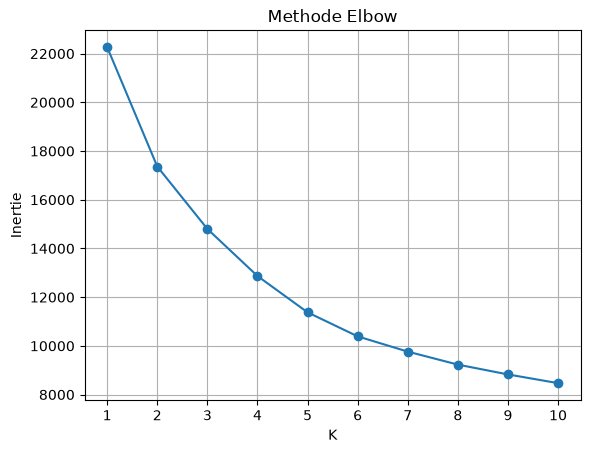

In [51]:
import matplotlib.pyplot as plt

plt.plot(K, kmeans_inerties, marker='o')

plt.xlabel("K")
plt.ylabel("Inertie")
plt.title("Methode Elbow")

plt.xticks(K)
plt.grid()
plt.show()

### Algorithme KMeans

1. Application de l'algo

In [27]:
# selon le graphique, le nombre optimal de clusters est 4
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(scaled_dataset)

# Ajouter les clusters aux donnees
clusters = kmeans.labels_

print("Les clusters :", clusters)

Les clusters : [1 0 2 ... 0 2 2]


recuperer l'inertie 

In [28]:
inertie_kmeans = kmeans.inertia_

print("Inertie K-Means :", inertie_kmeans)


Inertie K-Means : 14802.528721107978


2. Afficher le nombre d'elements dans chaque cluster

In [29]:
print(pd.Series(clusters).value_counts().sort_index())

0     570
1     975
2    2166
Name: count, dtype: int64


3. Coef de Silhouette

In [30]:
score_Kmedian = silhouette_score(scaled_dataset, clusters)
print("Coefficient de silhouette :", score_Kmedian)

Coefficient de silhouette : 0.22116527714205583


4. Interpretation des resutats:

Le coefficient de silhouette permet d'évaluer la qualité du clustering en mesurant la cohésion des observations au sein de leurs clusters et la séparation entre les différents clusters.

Pour K = 4, le coefficient obtenu est de 0,183 , ce qui indique une faible séparation entre les clusters.

En revanche, pour K = 3, le coefficient atteint 0,22. Cette amélioration indique une meilleure organisation des données en clusters, avec une séparation plus satisfaisante entre les groupes.

Ainsi, parmi ces deux configurations, K = 3 présente le meilleur résultat selon le coefficient de silhouette. Cependant, la qualité du clustering reste modérée et les groupes ne sont pas parfaitement séparés.

# 4. K-Medoids

Calculer la matrice des distances

In [31]:
# Calculer la matrice des distances euclidiennes
distances = euclidean_distances(scaled_dataset)

Appliquer KMedoid

In [32]:
# Appliquer K-Medoids avec 3 clusters
kmedoids_instance = kmedoids.KMedoids(
    n_clusters=3,
    method="fasterpam"
)

kmedoids_instance.fit(distances)
# Recuperer les clusters
clusters_kmedoids = kmedoids_instance.labels_

# Afficher les clusters
print("Les clusters :", clusters_kmedoids)



Les clusters : [1 1 1 ... 0 0 0]


Afficher le nombre d'observations dans chaque cluster

In [33]:

print(pd.Series(clusters_kmedoids).value_counts().sort_index())

0    1656
1    1205
2     850
Name: count, dtype: int64


Calculer le Ceof de Silhouette

In [34]:
# Calculer le coefficient de silhouette
score_kmedoids = silhouette_score(scaled_dataset,clusters_kmedoids)
print("Coefficient de silhouette K-Medoids :", score_kmedoids)

Coefficient de silhouette K-Medoids : 0.17417281467546503


Analyse des Resultats

In [35]:
print("Silhouette K-Means :", score_Kmedian)
print("Silhouette K-Medoids :", score_kmedoids)

Silhouette K-Means : 0.22116527714205583
Silhouette K-Medoids : 0.17417281467546503


### 5.Comparaison des performances : 

5.1.Histogramme des inerties : 

calculer l'inertie de K-Medoids avec distance seulement 

In [36]:
inertie_kmedoids = kmedoids_instance.inertia_

print("Inertie K-Medoids :", inertie_kmedoids)

Inertie K-Medoids : 6965.458314005789


calculer l'inertie de K-Medoids avec distance au carré

In [37]:

# Récupérer les indices des médoïdes
indices_medoids = kmedoids_instance.medoid_indices_

# Récupérer les observations correspondant aux médoïdes
X = scaled_dataset.to_numpy()
medoids = X[indices_medoids]

# Calculer les distances entre chaque observation et chaque médoïde
distances = euclidean_distances(X, medoids)

# Garder la distance minimale pour chaque observation
distances_min = np.min(distances, axis=1)

# Calculer l'inertie (somme des distances au carré)
inertie_kmedoids = np.sum(distances_min ** 2)

print("Inertie K-Medoids :", inertie_kmedoids)

Inertie K-Medoids : 16023.463491478651


Creer l'histogramme

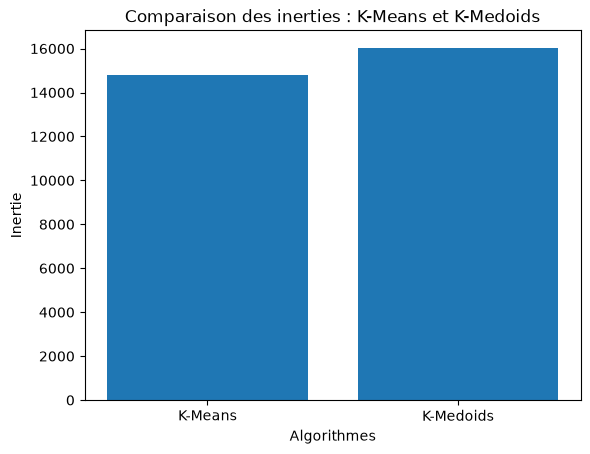

In [38]:
methodes = ["K-Means", "K-Medoids"]
inerties = [inertie_kmeans, inertie_kmedoids]

plt.bar(methodes, inerties)
plt.xlabel("Algorithmes")
plt.ylabel("Inertie")
plt.title("Comparaison des inerties : K-Means et K-Medoids")

plt.show()

5.2 Analyse :



**Comparaison des mesures de performance :**

Les coefficients de silhouette obtenus sont de 0,2212 pour K-Means et de 0,1729 pour K-Medoids. K-Means présente donc un meilleur coefficient de silhouette, ce qui indique une meilleure cohésion des clusters et une meilleure séparation entre eux. Cependant, ces deux valeurs restent relativement faibles, ce qui suggère que les clusters ne sont pas très bien séparés.

**Comparaison des histogrammes d'inertie :**

D'après l'histogramme, l'inertie de K-Means est d'environ 14 800, contre 16 000 pour K-Medoids. K-Means présente donc une inertie plus faible, ce qui traduit une dispersion moins importante des observations autour des représentants de leurs clusters. Il produit ainsi des groupes plus compacts selon ce critère.

**Avantages et inconvénients des deux méthodes :**

- **K-Means :** cette méthode est simple à mettre en œuvre et généralement rapide en exécution. Elle est adaptée aux grands jeux de données. Cependant, elle est sensible aux valeurs aberrantes, car les centroïdes sont calculés à partir des moyennes des observations. Elle peut également être influencée par l'initialisation des centroïdes.
- **K-Medoids :** cette méthode utilise des observations réelles comme représentants des clusters, ce qui la rend plus robuste face aux valeurs aberrantes. En revanche, elle présente généralement un coût de calcul plus élevé que K-Means, notamment lorsque le nombre d'observations est important.

**Conclusion :**

D'après les résultats obtenus, K-Means présente de meilleures performances que K-Medoids sur notre jeu de données, aussi bien en termes de coefficient de silhouette que d'inertie. Il permet d'obtenir des clusters plus compacts et mieux séparés selon les mesures utilisées. K-Medoids conserve néanmoins l'avantage d'être plus robuste face aux valeurs aberrantes grâce à l'utilisation d'observations réelles comme représentants des clusters.